# Deployable Prediction Model

A lightweight predictor for component integrity. It loads the posterior samples saved by `02_hierarchical_degradation_model.ipynb` (the enhanced hierarchical model) and exposes a `predict()` function for any component at any time. No sampler or `numpyro` is needed at prediction time.

### Requirements
- `../results/model_samples.npz`: posterior samples (written by notebook 02)
- `../data/bml-component-data.csv`: only needed for the illustrative plots below
- `numpy` (the only runtime dependency of the model itself)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Load Pre-trained Model

In [2]:
class DeployableModel:
    """
    Encapsulates the pre-trained Bayesian hierarchical model.
    Loads posterior samples from disk and provides prediction capability.
    """
    def __init__(self, model_path='../results/model_samples.npz'):
        data = np.load(model_path)
        self.u_i = data['u_i']          # (n_samples, 75)
        self.v_i = data['v_i']          # (n_samples, 75)
        self.w = data['w']              # (n_samples, 5)
        self.sigma_y = data['sigma_y']  # (n_samples,)
        self.X_features = data['X_features']  # (75, 5)
        self.n_samples = self.u_i.shape[0]
        print(f"Model loaded: {self.n_samples} posterior samples for {self.u_i.shape[1]} components")

# Load
model_obj = DeployableModel('../results/model_samples.npz')

Model loaded: 8000 posterior samples for 75 components


## Predict Function

Signature: `pred_mean, pred_std = predict(index, day, model_obj)`

- `index`: component index (0-74)
- `day`: time $t$ for prediction (scalar or array)
- `model_obj`: the loaded `DeployableModel` object

Returns the mean and standard deviation of the predictive distribution
(function uncertainty only, excluding noise $\sigma_y$).

In [3]:
def predict(index, day, model_obj):
    """
    Predict component integrity using the pre-trained Bayesian model.

    Parameters
    index : int
        Component index (0-74).
    day : float or np.ndarray
        Time(s) at which to predict.
    model_obj : DeployableModel
        Pre-loaded model object.

    Returns
    pred_mean : np.ndarray
        Posterior predictive mean at each time.
    pred_std : np.ndarray
        Posterior predictive std (function uncertainty) at each time.
    """
    day = np.atleast_1d(np.asarray(day, dtype=float))

    # Retrieve per-component samples
    u = model_obj.u_i[:, index]    # (n_samples,)
    v = model_obj.v_i[:, index]    # (n_samples,)
    x_i = model_obj.X_features[index]  # (5,)

    # Effective decay = v_i + w . x_i
    wx = model_obj.w @ x_i         # (n_samples,)
    decay = v + wx                 # (n_samples,)

    # f(t) = u * exp(-decay * t / 100) for each sample and each t
    t = day.reshape(1, -1)          # (1, T)
    F = u.reshape(-1, 1) * np.exp(-decay.reshape(-1, 1) * t / 100.0)  # (n_samples, T)

    pred_mean = np.mean(F, axis=0)
    pred_std = np.std(F, axis=0)

    return pred_mean, pred_std

## Illustrative examples

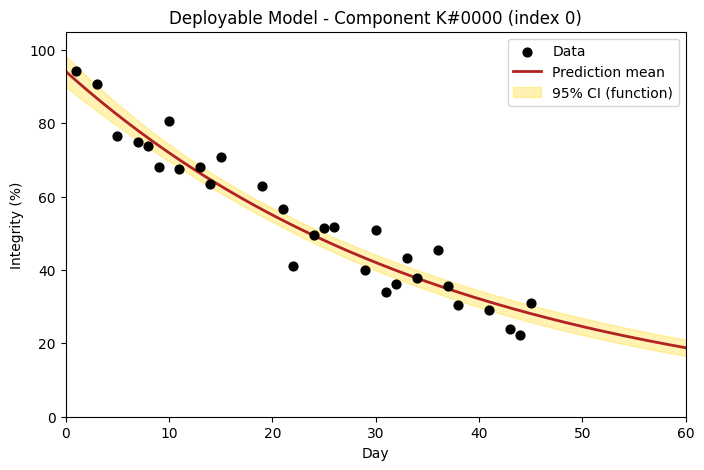

In [4]:
import pandas as pd
df = pd.read_csv('../data/bml-component-data.csv')

# Example 1: Predict for component 0 (data-rich) at various times
t_pred = np.linspace(0, 60, 200)
mean_0, std_0 = predict(0, t_pred, model_obj)

comp_data = df[df['index'] == 0]
plt.figure(figsize=(8, 5))
plt.scatter(comp_data['day'], comp_data['integrity'], s=40, zorder=5, color='black', label='Data')
plt.plot(t_pred, mean_0, color='firebrick', lw=2, label='Prediction mean')
plt.fill_between(t_pred, mean_0 - 1.96*std_0, mean_0 + 1.96*std_0,
                 alpha=0.3, color='gold', label='95% CI (function)')
plt.xlabel('Day'); plt.ylabel('Integrity (%)')
plt.title('Deployable Model - Component K#0000 (index 0)')
plt.legend(); plt.xlim(0, 60); plt.ylim(0, 105)
plt.show()

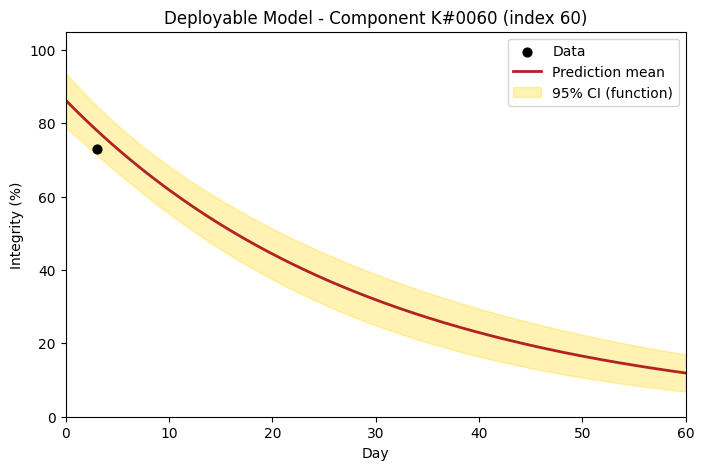

In [5]:
# Example 2: Predict for a sparse-data component (index 60)
mean_60, std_60 = predict(60, t_pred, model_obj)

comp_data = df[df['index'] == 60]
plt.figure(figsize=(8, 5))
plt.scatter(comp_data['day'], comp_data['integrity'], s=40, zorder=5, color='black', label='Data')
plt.plot(t_pred, mean_60, color='firebrick', lw=2, label='Prediction mean')
plt.fill_between(t_pred, mean_60 - 1.96*std_60, mean_60 + 1.96*std_60,
                 alpha=0.3, color='gold', label='95% CI (function)')
plt.xlabel('Day'); plt.ylabel('Integrity (%)')
plt.title('Deployable Model - Component K#0060 (index 60)')
plt.legend(); plt.xlim(0, 60); plt.ylim(0, 105)
plt.show()

In [6]:
# Example 3: Single-point prediction
mean_val, std_val = predict(50, 30.0, model_obj)
print(f"Component K#0050 at day 30:")
print(f"  Predicted integrity: {mean_val[0]:.2f}% ± {std_val[0]:.2f}%")

Component K#0050 at day 30:
  Predicted integrity: 33.96% ± 3.29%


In [7]:
# Example 4: All test components at day 30
print(f"{'Component':<12} {'Mean':>8} {'Std':>8}")
print("-" * 30)
for idx in range(50, 75):
    m, s = predict(idx, 30.0, model_obj)
    comp_id = df[df['index'] == idx]['ID'].iloc[0]
    print(f"{comp_id:<12} {m[0]:>8.2f} {s[0]:>8.2f}")

Component        Mean      Std
------------------------------
K#0050          33.96     3.29
K#0051          16.82     1.62
K#0052           4.73     0.65
K#0053          30.69     2.72
K#0054          41.26     4.00
K#0055          26.01     3.08
K#0056          21.23     2.11
K#0057          50.97     5.03
K#0058          13.04     1.90
K#0059          29.20     3.91
K#0060          31.90     3.56
K#0061          41.31     3.87
K#0062          37.18     4.04
K#0063          41.15     3.96
K#0064          55.98     5.49
K#0065          21.78     2.43
K#0066          11.91     2.17
K#0067           8.58     1.15
K#0068          39.99     5.57
K#0069          16.63     2.44
K#0070          22.71     2.32
K#0071          25.72     2.80
K#0072          35.22     3.22
K#0073          23.73     2.74
K#0074          42.73     3.78
